In [2]:
import pandas as pd
import numpy as np

In [3]:
DATA_PATH = "../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(DATA_PATH)

In [4]:
print("Dataset Shape:")
print(df.shape)

print("\n" + "=" * 60)

print("Column Names:")
print(df.columns.tolist())

print("\n" + "=" * 60)

print("First 5 Rows:")
display(df.head())

Dataset Shape:
(7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

First 5 Rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
print("Data Types and Non-Null Counts:")
df.info()

Data Types and Non-Null Counts:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  704

In [6]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
missing = df.isnull().sum()

missing_summary = pd.DataFrame({
    "missing_count": missing,
    "missing_percentage": (missing / len(df)) * 100
})

missing_summary = missing_summary[
    missing_summary["missing_count"] > 0
].sort_values("missing_count", ascending=False)

missing_summary

,missing_count,missing_percentage


In [8]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


In [10]:
print("Churn Counts:")
print(df["Churn"].value_counts())

print("\nChurn Percentages:")
print(
    df["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Churn Counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [11]:
# Investigate TotalCharges values that cannot be converted to numbers

total_charges_numeric = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

invalid_total_charges = df[
    total_charges_numeric.isna()
]

print("Invalid TotalCharges values:", len(invalid_total_charges))

display(
    invalid_total_charges[
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

Invalid TotalCharges values: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [12]:
zero_tenure = df[df["tenure"] == 0]

print("Customers with tenure = 0:", len(zero_tenure))

display(
    zero_tenure[
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)


Customers with tenure = 0: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [13]:
# Inspect the exact raw representation of the problematic values

invalid_mask = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
).isna()

print("Raw representations of invalid TotalCharges:")
print(
    df.loc[invalid_mask, "TotalCharges"]
    .map(repr)
    .value_counts()
)

Raw representations of invalid TotalCharges:
TotalCharges
' '    11
Name: count, dtype: int64


In [14]:
# ============================================
# CLEAN TOTALCHARGES
# ============================================

df_clean = df.copy()

# Preserve information about originally blank values
df_clean["TotalChargesMissing"] = (
    df_clean["TotalCharges"]
    .astype(str)
    .str.strip()
    .eq("")
    .astype(int)
)

# Convert TotalCharges to numeric
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

# Domain-based handling:
# Customers with tenure = 0 have no accumulated charges
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

print("TotalCharges dtype:", df_clean["TotalCharges"].dtype)
print(
    "Remaining missing TotalCharges:",
    df_clean["TotalCharges"].isna().sum()
)
print(
    "Originally blank TotalCharges:",
    df_clean["TotalChargesMissing"].sum()
)

TotalCharges dtype: float64
Remaining missing TotalCharges: 0
Originally blank TotalCharges: 11


In [15]:
# ============================================
# VALIDATE CLEANING
# ============================================

print("Dataset shape:", df_clean.shape)

print("\nData types:")
print(df_clean.dtypes)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nTotalCharges statistics:")
print(df_clean["TotalCharges"].describe())

Dataset shape: (7043, 22)

Data types:
customerID                 str
gender                     str
SeniorCitizen            int64
Partner                    str
Dependents                 str
tenure                   int64
PhoneService               str
MultipleLines              str
InternetService            str
OnlineSecurity             str
OnlineBackup               str
DeviceProtection           str
TechSupport                str
StreamingTV                str
StreamingMovies            str
Contract                   str
PaperlessBilling           str
PaymentMethod              str
MonthlyCharges         float64
TotalCharges           float64
Churn                      str
TotalChargesMissing      int64
dtype: object

Missing values:
customerID             0
gender                 0
SeniorCitizen          0
Partner                0
Dependents             0
tenure                 0
PhoneService           0
MultipleLines          0
InternetService        0
OnlineSecurity         

In [16]:
# ============================================
# SAVE PROCESSED DATASET
# ============================================

from pathlib import Path

processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

output_path = processed_dir / "customer_churn_clean.csv"

df_clean.to_csv(output_path, index=False)

print(f"Processed dataset saved to: {output_path}")

Processed dataset saved to: ..\data\processed\customer_churn_clean.csv


In [17]:
# ============================================
# EDA — LOAD PROCESSED DATA
# ============================================

import pandas as pd
import numpy as np

processed_path = "../data/processed/customer_churn_clean.csv"

df_eda = pd.read_csv(processed_path)

print("EDA dataset shape:", df_eda.shape)
df_eda.head()

EDA dataset shape: (7043, 22)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TotalChargesMissing
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0


In [18]:
# Convert churn into a binary indicator for analysis

df_eda["ChurnFlag"] = (
    df_eda["Churn"]
    .map({"No": 0, "Yes": 1})
)

print(df_eda["ChurnFlag"].value_counts())

ChurnFlag
0    5174
1    1869
Name: count, dtype: int64


In [19]:
overall_churn_rate = df_eda["ChurnFlag"].mean() * 100

print(f"Overall churn rate: {overall_churn_rate:.2f}%")

Overall churn rate: 26.54%


In [20]:
import sys
print(sys.executable)

d:\DataScience_Projects\customer-churn-intelligence\venv\Scripts\python.exe


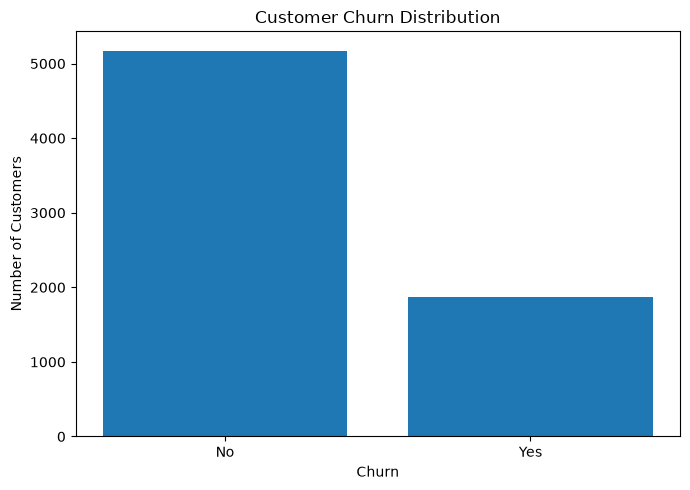

In [21]:
import matplotlib.pyplot as plt

churn_counts = df_eda["Churn"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    churn_counts.index,
    churn_counts.values
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [22]:
import sys

print(sys.executable)

d:\DataScience_Projects\customer-churn-intelligence\venv\Scripts\python.exe


In [23]:
contract_churn = (
    df_eda
    .groupby("Contract")["ChurnFlag"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(contract_churn)

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: ChurnFlag, dtype: float64


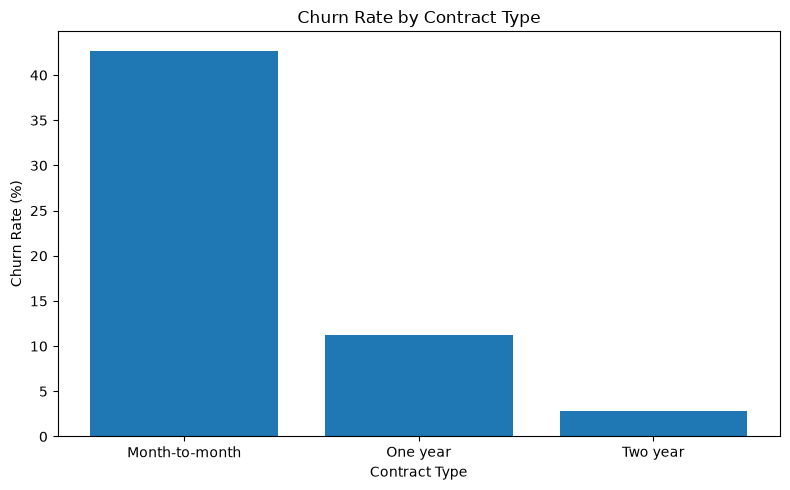

In [24]:
plt.figure(figsize=(8, 5))

plt.bar(
    contract_churn.index,
    contract_churn.values
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

In [25]:
df_eda["TenureGroup"] = pd.cut(
    df_eda["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=[
        "0–6 months",
        "7–12 months",
        "13–24 months",
        "25–48 months",
        "49–72 months"
    ]
)

tenure_churn = (
    df_eda
    .groupby("TenureGroup", observed=False)["ChurnFlag"]
    .mean()
    .mul(100)
)

print(tenure_churn)

TenureGroup
0–6 months      52.937205
7–12 months     35.886525
13–24 months    28.710938
25–48 months    20.388959
49–72 months     9.513176
Name: ChurnFlag, dtype: float64


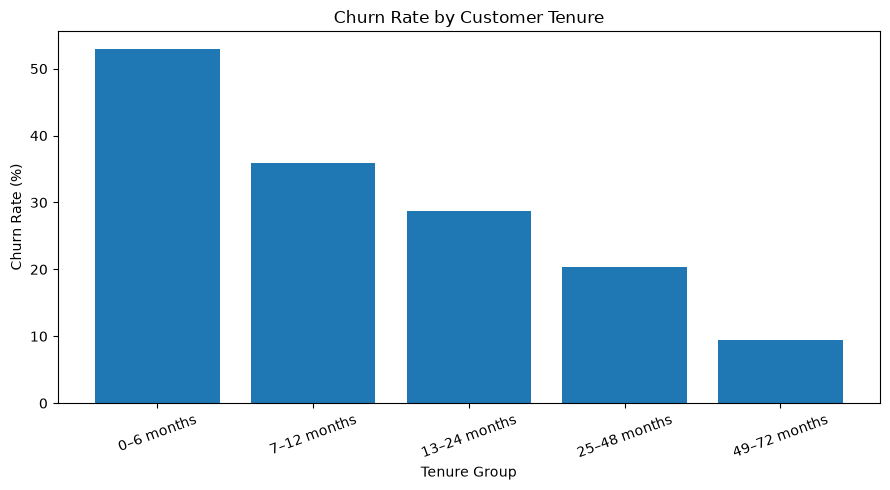

In [26]:
plt.figure(figsize=(9, 5))

plt.bar(
    tenure_churn.index.astype(str),
    tenure_churn.values
)

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [27]:
payment_churn = (
    df_eda
    .groupby("PaymentMethod")["ChurnFlag"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(payment_churn)

PaymentMethod
Electronic check             45.285412
Mailed check                 19.106700
Bank transfer (automatic)    16.709845
Credit card (automatic)      15.243101
Name: ChurnFlag, dtype: float64


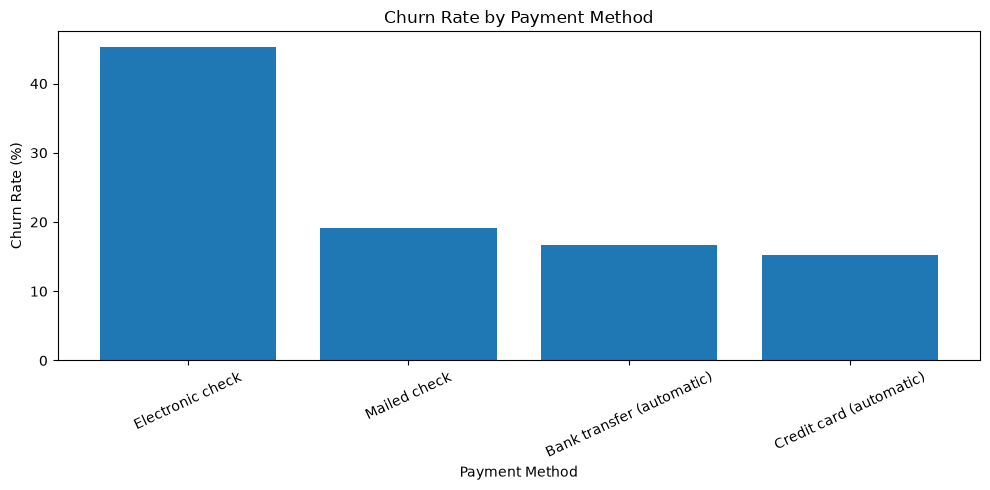

In [28]:
plt.figure(figsize=(10, 5))

plt.bar(
    payment_churn.index,
    payment_churn.values
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=25)

plt.tight_layout()
plt.show()

In [29]:
# ============================================
# STEP 16.1 — CONTRACT × TENURE
# ============================================

contract_tenure_churn = (
    df_eda
    .groupby(["Contract", "TenureGroup"], observed=False)["ChurnFlag"]
    .mean()
    .mul(100)
    .reset_index()
)

print(contract_tenure_churn)

          Contract   TenureGroup  ChurnFlag
0   Month-to-month    0–6 months  55.201699
1   Month-to-month   7–12 months  41.996558
2   Month-to-month  13–24 months  37.720488
3   Month-to-month  25–48 months  32.917706
4   Month-to-month  49–72 months  26.023392
5         One year    0–6 months  10.256410
6         One year   7–12 months  10.588235
7         One year  13–24 months   8.121827
8         One year  25–48 months  10.617761
9         One year  49–72 months  12.933754
10        Two year    0–6 months   0.000000
11        Two year   7–12 months   0.000000
12        Two year  13–24 months   0.000000
13        Two year  25–48 months   2.189781
14        Two year  49–72 months   3.325416


In [30]:
contract_tenure_pivot = contract_tenure_churn.pivot(
    index="TenureGroup",
    columns="Contract",
    values="ChurnFlag"
)

print(contract_tenure_pivot.round(2))

Contract      Month-to-month  One year  Two year
TenureGroup                                     
0–6 months             55.20     10.26      0.00
7–12 months            42.00     10.59      0.00
13–24 months           37.72      8.12      0.00
25–48 months           32.92     10.62      2.19
49–72 months           26.02     12.93      3.33


In [31]:
# ============================================
# STEP 16.2 — INTERNET SERVICE × CONTRACT
# ============================================

internet_contract_churn = (
    df_eda
    .groupby(
        ["InternetService", "Contract"]
    )["ChurnFlag"]
    .mean()
    .mul(100)
    .reset_index()
)

internet_contract_pivot = internet_contract_churn.pivot(
    index="InternetService",
    columns="Contract",
    values="ChurnFlag"
)

print(internet_contract_pivot.round(2))

Contract         Month-to-month  One year  Two year
InternetService                                    
DSL                       32.22      9.30      1.91
Fiber optic               54.61     19.29      7.23
No                        18.89      2.47      0.78


In [32]:
# ============================================
# STEP 16.3 — MONTHLY CHARGES
# ============================================

monthly_charge_summary = (
    df_eda
    .groupby("Churn")["MonthlyCharges"]
    .agg(["count", "mean", "median", "std"])
)

print(monthly_charge_summary.round(2))

       count   mean  median    std
Churn                             
No      5174  61.27   64.43  31.09
Yes     1869  74.44   79.65  24.67


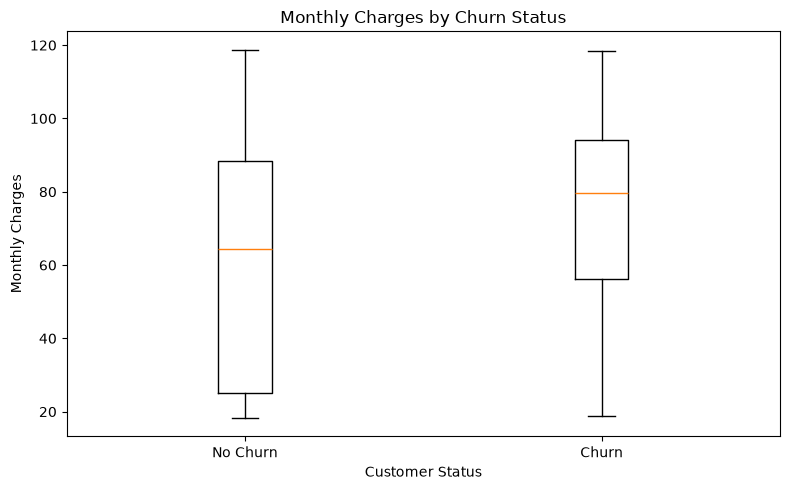

In [33]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        df_eda.loc[df_eda["Churn"] == "No", "MonthlyCharges"],
        df_eda.loc[df_eda["Churn"] == "Yes", "MonthlyCharges"]
    ],
    tick_labels=["No Churn", "Churn"]
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Customer Status")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

In [34]:
# ============================================
# STEP 16.4 — SENIOR CITIZEN × CONTRACT
# ============================================

senior_contract_churn = (
    df_eda
    .groupby(
        ["SeniorCitizen", "Contract"]
    )["ChurnFlag"]
    .mean()
    .mul(100)
    .reset_index()
)

senior_contract_pivot = senior_contract_churn.pivot(
    index="Contract",
    columns="SeniorCitizen",
    values="ChurnFlag"
)

senior_contract_pivot = senior_contract_pivot.rename(
    columns={
        0: "Non-Senior",
        1: "Senior"
    }
)

print(senior_contract_pivot.round(2))

SeniorCitizen   Non-Senior  Senior
Contract                          
Month-to-month       39.57   54.65
One year             10.68   15.26
Two year              2.71    4.14


In [35]:
# ============================================
# STEP 16.5 — HIGH-RISK SEGMENT
# ============================================

high_risk = df_eda[
    (df_eda["Contract"] == "Month-to-month") &
    (df_eda["tenure"] <= 12)
]

print("High-risk segment size:", len(high_risk))

print(
    "High-risk segment churn rate:",
    round(high_risk["ChurnFlag"].mean() * 100, 2),
    "%"
)

High-risk segment size: 1994
High-risk segment churn rate: 51.35 %


In [36]:
print(
    "Overall churn rate:",
    round(df_eda["ChurnFlag"].mean() * 100, 2),
    "%"
)

Overall churn rate: 26.54 %


In [37]:
# ============================================
# STEP 16.6 — CATEGORICAL CHURN ANALYSIS
# ============================================

categorical_features = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

for feature in categorical_features:
    print("\n" + "=" * 60)
    print(feature)

    result = (
        df_eda
        .groupby(feature)["ChurnFlag"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    print(result.round(2))


gender
gender
Female    26.92
Male      26.16
Name: ChurnFlag, dtype: float64

SeniorCitizen
SeniorCitizen
1    41.68
0    23.61
Name: ChurnFlag, dtype: float64

Partner
Partner
No     32.96
Yes    19.66
Name: ChurnFlag, dtype: float64

Dependents
Dependents
No     31.28
Yes    15.45
Name: ChurnFlag, dtype: float64

PhoneService
PhoneService
Yes    26.71
No     24.93
Name: ChurnFlag, dtype: float64

MultipleLines
MultipleLines
Yes                 28.61
No                  25.04
No phone service    24.93
Name: ChurnFlag, dtype: float64

InternetService
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: ChurnFlag, dtype: float64

OnlineSecurity
OnlineSecurity
No                     41.77
Yes                    14.61
No internet service     7.40
Name: ChurnFlag, dtype: float64

OnlineBackup
OnlineBackup
No                     39.93
Yes                    21.53
No internet service     7.40
Name: ChurnFlag, dtype: float64

DeviceProtection
DeviceProtection

In [38]:
# ============================================
# STEP 16.7 — SAVE EDA DATASET
# ============================================

eda_path = "../data/processed/customer_churn_eda.csv"

df_eda.to_csv(
    eda_path,
    index=False
)

print(f"EDA dataset saved to: {eda_path}")

EDA dataset saved to: ../data/processed/customer_churn_eda.csv


In [39]:
# ============================================
# STEP 17.1 — LOAD CLEAN DATA FOR ML
# ============================================

import pandas as pd
import numpy as np

clean_path = "../data/processed/customer_churn_clean.csv"

df_ml = pd.read_csv(clean_path)

print("Dataset shape:", df_ml.shape)
print("\nColumns:")
print(df_ml.columns.tolist())

Dataset shape: (7043, 22)

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'TotalChargesMissing']


In [40]:
# ============================================
# STEP 17.2 — REMOVE NON-PREDICTIVE COLUMNS
# ============================================

df_ml = df_ml.drop(
    columns=["customerID"],
    errors="ignore"
)

print("Shape after removing customerID:", df_ml.shape)

Shape after removing customerID: (7043, 21)


In [41]:
# ============================================
# STEP 17.3 — CREATE TARGET VARIABLE
# ============================================

df_ml["Churn"] = (
    df_ml["Churn"]
    .map({
        "No": 0,
        "Yes": 1
    })
)

print(df_ml["Churn"].value_counts())
print("\nTarget distribution:")
print(df_ml["Churn"].value_counts(normalize=True).mul(100).round(2))

Churn
0    5174
1    1869
Name: count, dtype: int64

Target distribution:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


In [42]:
# ============================================
# STEP 17.4 — FEATURE ENGINEERING
# ============================================

df_ml["AverageMonthlyCharges"] = np.where(
    df_ml["tenure"] > 0,
    df_ml["TotalCharges"] / df_ml["tenure"],
    df_ml["MonthlyCharges"]
)

In [43]:
df_ml["TenureGroup"] = pd.cut(
    df_ml["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=[
        "0–6 months",
        "7–12 months",
        "13–24 months",
        "25–48 months",
        "49–72 months"
    ]
)

In [44]:
service_columns = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df_ml["ServiceCount"] = (
    df_ml[service_columns]
    .isin(["Yes"])
    .sum(axis=1)
)

In [45]:
df_ml["TotalChargesPerTenure"] = np.where(
    df_ml["tenure"] > 0,
    df_ml["TotalCharges"] / df_ml["tenure"],
    df_ml["MonthlyCharges"]
)

In [46]:
df_ml = df_ml.drop(
    columns=["TotalChargesPerTenure"]
)

In [47]:
df_ml["EarlyMonthToMonth"] = (
    (df_ml["Contract"] == "Month-to-month") &
    (df_ml["tenure"] <= 12)
).astype(int)

In [48]:
# ============================================
# STEP 17.6 — VALIDATE ENGINEERED FEATURES
# ============================================

engineered_features = [
    "AverageMonthlyCharges",
    "TenureGroup",
    "ServiceCount",
    "EarlyMonthToMonth"
]

print(df_ml[engineered_features].head())

print("\nFeature information:")
print(df_ml[engineered_features].info())

   AverageMonthlyCharges   TenureGroup  ServiceCount  EarlyMonthToMonth
0              29.850000    0–6 months             1                  1
1              55.573529  25–48 months             2                  0
2              54.075000    0–6 months             2                  1
3              40.905556  25–48 months             3                  0
4              75.825000    0–6 months             0                  1

Feature information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   AverageMonthlyCharges  7043 non-null   float64 
 1   TenureGroup            7043 non-null   category
 2   ServiceCount           7043 non-null   int64   
 3   EarlyMonthToMonth      7043 non-null   int64   
dtypes: category(1), float64(1), int64(2)
memory usage: 172.3 KB
None


In [49]:
print("\nSummary:")
print(
    df_ml[
        [
            "AverageMonthlyCharges",
            "ServiceCount",
            "EarlyMonthToMonth"
        ]
    ].describe()
)


Summary:
       AverageMonthlyCharges  ServiceCount  EarlyMonthToMonth
count            7043.000000   7043.000000        7043.000000
mean               64.762906      2.037910           0.283118
std                30.189796      1.847682           0.450545
min                13.775000      0.000000           0.000000
25%                35.935156      0.000000           0.000000
50%                70.337500      2.000000           0.000000
75%                90.174158      3.000000           1.000000
max               121.400000      6.000000           1.000000


In [50]:
# ============================================
# STEP 17.7 — X / y SPLIT
# ============================================

X = df_ml.drop(columns=["Churn"])
y = df_ml["Churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

X shape: (7043, 24)
y shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [51]:
# ============================================
# STEP 17.8 — IDENTIFY FEATURE TYPES
# ============================================

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'TotalChargesMissing', 'AverageMonthlyCharges', 'ServiceCount', 'EarlyMonthToMonth']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']


C:\Users\Hp\AppData\Local\Temp\ipykernel_10700\38146855.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [52]:
# ============================================
# STEP 17.9 — TRAIN / TEST SPLIT
# ============================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training samples: 5634
Testing samples: 1409

Training target distribution:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


In [53]:
# ============================================
# STEP 17.10 — PREPROCESSING PIPELINE
# ============================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [54]:
# ============================================
# STEP 17.11 — BASELINE MODEL
# ============================================

from sklearn.linear_model import LogisticRegression

baseline_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

print("Baseline pipeline created.")

Baseline pipeline created.


In [55]:
# ============================================
# STEP 17.12 — TRAIN BASELINE
# ============================================

baseline_model.fit(
    X_train,
    y_train
)

print("Baseline model trained successfully.")

Baseline model trained successfully.


In [56]:
# ============================================
# STEP 17.13 — BASELINE EVALUATION
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

y_pred = baseline_model.predict(X_test)
y_prob = baseline_model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(
    accuracy_score(y_test, y_pred), 4
))

print("Precision:", round(
    precision_score(y_test, y_pred), 4
))

print("Recall:", round(
    recall_score(y_test, y_pred), 4
))

print("F1 Score:", round(
    f1_score(y_test, y_pred), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, y_prob), 4
))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred
    )
)

Accuracy: 0.7977
Precision: 0.6529
Recall: 0.508
F1 Score: 0.5714
ROC-AUC: 0.8456

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.65      0.51      0.57       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409


Confusion Matrix:
[[934 101]
 [184 190]]


In [57]:
# ============================================
# STEP 17.1 — MODELING DATASET
# ============================================

df_model = df_eda.copy()

# Remove identifiers / analysis-only columns
df_model = df_model.drop(
    columns=["customerID", "ChurnFlag", "TenureGroup"],
    errors="ignore"
)

# Convert target to binary
df_model["Churn"] = df_model["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Modeling shape:", df_model.shape)
print("\nTarget distribution:")
print(df_model["Churn"].value_counts())

Modeling shape: (7043, 21)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [58]:
# ============================================
# STEP 17.2 — FEATURES AND TARGET
# ============================================

X = df_model.drop(columns=["Churn"])
y = df_model["Churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 20)
y shape: (7043,)


In [59]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining churn rate:")
print(y_train.mean())

print("\nTesting churn rate:")
print(y_test.mean())

Training samples: 5634
Testing samples: 1409

Training churn rate:
0.2653532126375577

Testing churn rate:
0.2654364797728886


In [60]:
# ============================================
# STEP 17.4 — FEATURE TYPES
# ============================================

categorical_features = X.select_dtypes(
    include=["object", "string"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'TotalChargesMissing']


In [61]:
# ============================================
# STEP 17.5 — PREPROCESSING PIPELINE
# ============================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [62]:
# ============================================
# STEP 17.6 — LOGISTIC REGRESSION BASELINE
# ============================================

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression training complete.")

Logistic Regression training complete.


In [63]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

y_pred = logistic_pipeline.predict(X_test)
y_prob = logistic_pipeline.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8062
Precision: 0.6583
Recall: 0.5615
F1 Score: 0.6061
ROC-AUC: 0.8423

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


Confusion Matrix:
[[926 109]
 [164 210]]


In [64]:
# ============================================
# STEP 17.1 — BUSINESS ERROR ANALYSIS
# ============================================

tn, fp, fn, tp = 926, 109, 164, 210

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives  :", tp)

print("\nChurners correctly identified:", tp)
print("Churners missed:", fn)

print(
    "\nChurn detection rate:",
    round(tp / (tp + fn) * 100, 2),
    "%"
)

True Negatives : 926
False Positives: 109
False Negatives: 164
True Positives  : 210

Churners correctly identified: 210
Churners missed: 164

Churn detection rate: 56.15 %


In [65]:
# ============================================
# STEP 17.2 — MODEL COMPARISON
# ============================================

model_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],
    "Previous Model": [
        0.7977,
        0.6529,
        0.5080,
        0.5714,
        0.8456
    ],
    "New Model": [
        0.8062,
        0.6583,
        0.5615,
        0.6061,
        0.8423
    ]
})

print(model_comparison.round(4))

      Metric  Previous Model  New Model
0   Accuracy          0.7977     0.8062
1  Precision          0.6529     0.6583
2     Recall          0.5080     0.5615
3         F1          0.5714     0.6061
4    ROC-AUC          0.8456     0.8423


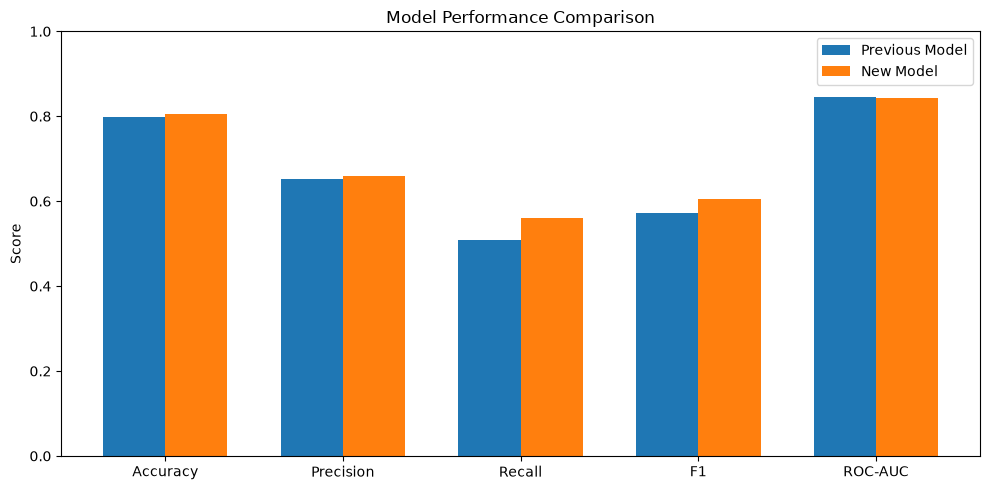

In [66]:
plt.figure(figsize=(10, 5))

x = np.arange(len(model_comparison))
width = 0.35

plt.bar(
    x - width / 2,
    model_comparison["Previous Model"],
    width,
    label="Previous Model"
)

plt.bar(
    x + width / 2,
    model_comparison["New Model"],
    width,
    label="New Model"
)

plt.xticks(x, model_comparison["Metric"])
plt.ylabel("Score")
plt.title("Model Performance Comparison")
plt.ylim(0, 1)

plt.legend()
plt.tight_layout()
plt.show()

In [67]:
# ============================================
# STEP 17.4 — FEATURE ENGINEERING DATASET
# ============================================

df_model = df_eda.copy()

print("Starting shape:", df_model.shape)

Starting shape: (7043, 24)


In [68]:
drop_columns = [
    "customerID",
    "Churn",
    "ChurnFlag",
    "TenureGroup"
]

df_model = df_model.drop(
    columns=drop_columns
)

print("Modeling shape:", df_model.shape)

Modeling shape: (7043, 20)


In [69]:
X = df_model.copy()
y = df_eda["ChurnFlag"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 20)
y shape: (7043,)


In [70]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

print("\nTraining churn rate:")
print(round(y_train.mean() * 100, 2), "%")

print("\nTesting churn rate:")
print(round(y_test.mean() * 100, 2), "%")

Training samples: 5634
Testing samples : 1409

Training churn rate:
26.54 %

Testing churn rate:
26.54 %


In [71]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numeric features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'TotalChargesMissing']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\Hp\AppData\Local\Temp\ipykernel_10700\1299309325.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [72]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [73]:
# ============================================
# STEP 18.1 — LOGISTIC REGRESSION PIPELINE
# ============================================

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

print("Logistic Regression pipeline created.")

Logistic Regression pipeline created.


In [74]:
# ============================================
# STEP 18.2 — TRAIN LOGISTIC REGRESSION
# ============================================

logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [75]:
# ============================================
# STEP 18.3 — LOGISTIC REGRESSION EVALUATION
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

y_pred_lr = logistic_pipeline.predict(X_test)
y_prob_lr = logistic_pipeline.predict_proba(X_test)[:, 1]

lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr)
lr_recall = recall_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)
lr_auc = roc_auc_score(y_test, y_prob_lr)

print(f"Accuracy : {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall   : {lr_recall:.4f}")
print(f"F1 Score : {lr_f1:.4f}")
print(f"ROC-AUC  : {lr_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Accuracy : 0.7388
Precision: 0.5052
Recall   : 0.7834
F1 Score : 0.6143
ROC-AUC  : 0.8418

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Confusion Matrix:
[[748 287]
 [ 81 293]]


In [76]:
# ============================================
# STEP 18.4 — RANDOM FOREST PIPELINE
# ============================================

from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=None,
                min_samples_split=5,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest pipeline created.")

Random Forest pipeline created.


In [77]:
# ============================================
# TRAIN RANDOM FOREST
# ============================================

rf_pipeline.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [78]:
# ============================================
# RANDOM FOREST EVALUATION
# ============================================

y_pred_rf = rf_pipeline.predict(X_test)
y_prob_rf = rf_pipeline.predict_proba(X_test)[:, 1]

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_auc = roc_auc_score(y_test, y_prob_rf)

print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1 Score : {rf_f1:.4f}")
print(f"ROC-AUC  : {rf_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Accuracy : 0.7622
Precision: 0.5396
Recall   : 0.7112
F1 Score : 0.6136
ROC-AUC  : 0.8335

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.78      0.83      1035
           1       0.54      0.71      0.61       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409


Confusion Matrix:
[[808 227]
 [108 266]]


In [79]:
import xgboost

print("XGBoost version:", xgboost.__version__)

XGBoost version: 3.2.0


In [80]:
# ============================================
# STEP 18.5 — XGBOOST PIPELINE
# ============================================

from xgboost import XGBClassifier

xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            XGBClassifier(
                n_estimators=300,
                max_depth=4,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("XGBoost pipeline created.")

XGBoost pipeline created.


In [81]:
# ============================================
# TRAIN XGBOOST
# ============================================

xgb_pipeline.fit(X_train, y_train)

print("XGBoost training completed.")

XGBoost training completed.


In [82]:
# ============================================
# XGBOOST EVALUATION
# ============================================

y_pred_xgb = xgb_pipeline.predict(X_test)
y_prob_xgb = xgb_pipeline.predict_proba(X_test)[:, 1]

xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb)
xgb_recall = recall_score(y_test, y_pred_xgb)
xgb_f1 = f1_score(y_test, y_pred_xgb)
xgb_auc = roc_auc_score(y_test, y_prob_xgb)

print(f"Accuracy : {xgb_accuracy:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall   : {xgb_recall:.4f}")
print(f"F1 Score : {xgb_f1:.4f}")
print(f"ROC-AUC  : {xgb_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

Accuracy : 0.7984
Precision: 0.6471
Recall   : 0.5294
F1 Score : 0.5824
ROC-AUC  : 0.8401

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.65      0.53      0.58       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409


Confusion Matrix:
[[927 108]
 [176 198]]


In [83]:
# ============================================
# STEP 18.6 — MODEL COMPARISON
# ============================================

model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        lr_accuracy,
        rf_accuracy,
        xgb_accuracy
    ],
    "Precision": [
        lr_precision,
        rf_precision,
        xgb_precision
    ],
    "Recall": [
        lr_recall,
        rf_recall,
        xgb_recall
    ],
    "F1": [
        lr_f1,
        rf_f1,
        xgb_f1
    ],
    "ROC-AUC": [
        lr_auc,
        rf_auc,
        xgb_auc
    ]
})

print(
    model_results
    .sort_values("ROC-AUC", ascending=False)
    .round(4)
)

                 Model  Accuracy  Precision  Recall      F1  ROC-AUC
0  Logistic Regression    0.7388     0.5052  0.7834  0.6143   0.8418
2              XGBoost    0.7984     0.6471  0.5294  0.5824   0.8401
1        Random Forest    0.7622     0.5396  0.7112  0.6136   0.8335


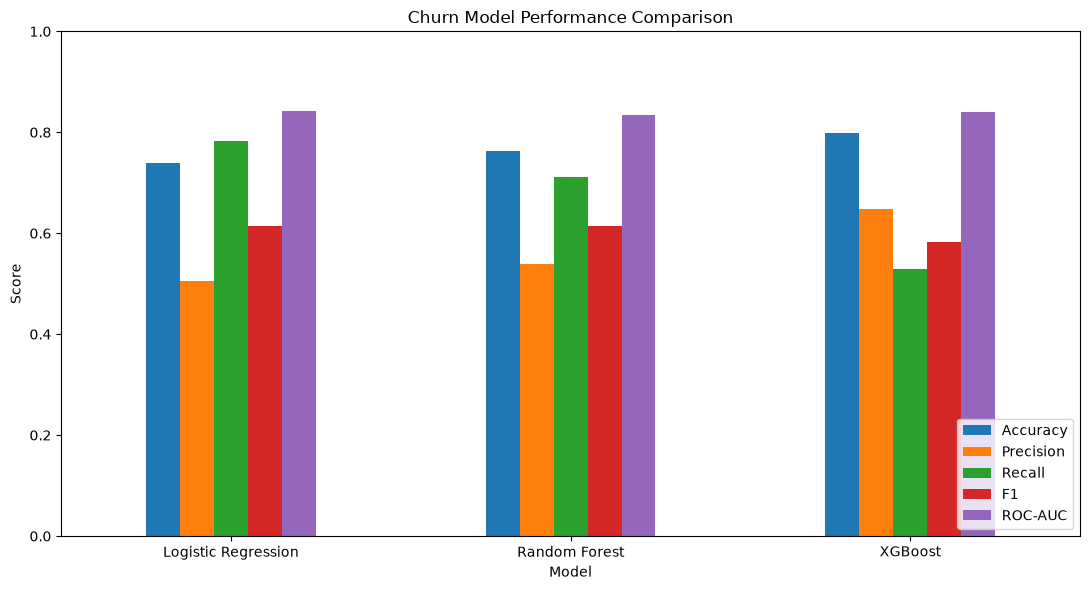

In [84]:
# ============================================
# MODEL COMPARISON CHART
# ============================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

model_results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Churn Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

In [85]:
# ============================================
# STEP 19.1 — THRESHOLD OPTIMIZATION
# ============================================

import numpy as np
import pandas as pd

thresholds = np.arange(0.20, 0.71, 0.05)

threshold_results = []

for threshold in thresholds:

    predictions = (y_prob_xgb >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "Accuracy": accuracy_score(
            y_test,
            predictions
        )
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(4)

,Threshold,Precision,Recall,F1,Accuracy
0,0.20,0.4800,0.8342,0.6094,0.7161
1,0.25,0.5102,0.7995,0.6229,0.7431
2,0.30,0.5225,0.7460,0.6145,0.7516
3,0.35,0.5499,0.6925,0.6130,0.7679
4,0.40,0.5817,0.6471,0.6127,0.7828
5,0.45,0.6197,0.5882,0.6036,0.7949
6,0.50,0.6471,0.5294,0.5824,0.7984
7,0.55,0.6850,0.4652,0.5541,0.8013
8,0.60,0.7059,0.3850,0.4983,0.7942
9,0.65,0.7595,0.3209,0.4511,0.7928


In [86]:
# ============================================
# STEP 19.2 — BEST F1 THRESHOLD
# ============================================

best_f1_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

print("Best threshold based on F1:")
print(best_f1_row)

Best threshold based on F1:
Threshold    0.250000
Precision    0.510239
Recall       0.799465
F1           0.622917
Accuracy     0.743080
Name: 1, dtype: float64


In [87]:
# ============================================
# STEP 19.3 — BEST RECALL THRESHOLD
# ============================================

best_recall_row = threshold_df.loc[
    threshold_df["Recall"].idxmax()
]

print("Best threshold based on Recall:")
print(best_recall_row)

Best threshold based on Recall:
Threshold    0.200000
Precision    0.480000
Recall       0.834225
F1           0.609375
Accuracy     0.716111
Name: 0, dtype: float64


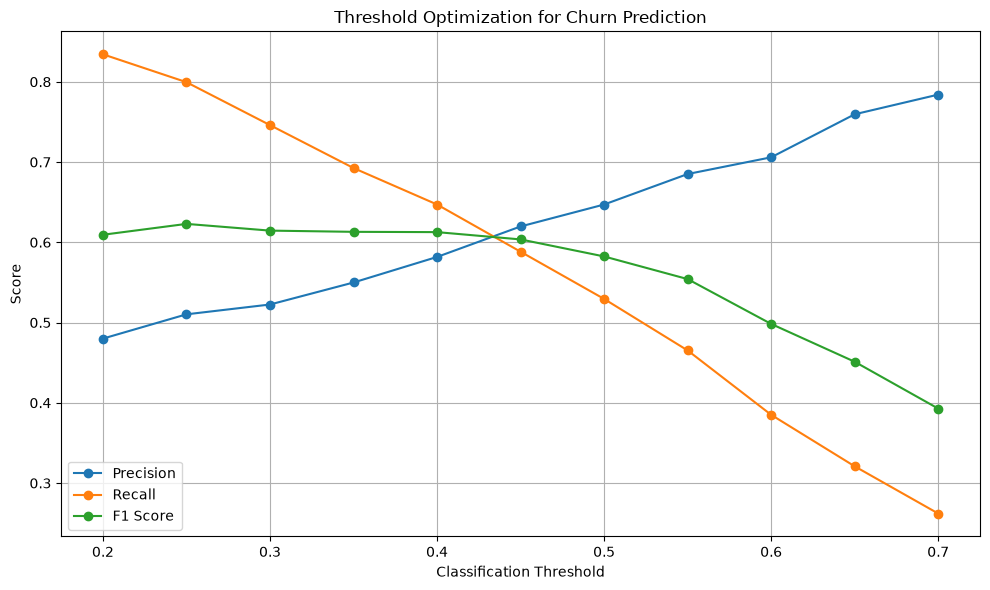

In [88]:
# ============================================
# STEP 19.4 — PRECISION / RECALL / F1
# ============================================

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Threshold Optimization for Churn Prediction")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [89]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.51.0


In [90]:
# ============================================
# STEP 20.2 — TRANSFORM FEATURES FOR SHAP
# ============================================

X_train_transformed = xgb_pipeline.named_steps[
    "preprocessor"
].transform(X_train)

X_test_transformed = xgb_pipeline.named_steps[
    "preprocessor"
].transform(X_test)

print("Training shape:", X_train_transformed.shape)
print("Testing shape :", X_test_transformed.shape)

Training shape: (5634, 46)
Testing shape : (1409, 46)


In [91]:
# ============================================
# STEP 20.3 — EXTRACT XGBOOST MODEL
# ============================================

xgb_model = xgb_pipeline.named_steps["model"]

print(xgb_model)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)


In [92]:
# ============================================
# STEP 20.4 — SHAP EXPLAINER
# ============================================

explainer = shap.TreeExplainer(xgb_model)

print("SHAP explainer created successfully.")

SHAP explainer created successfully.


In [93]:
# ============================================
# STEP 20.5 — CALCULATE SHAP VALUES
# ============================================

shap_values = explainer.shap_values(
    X_test_transformed
)

print("SHAP values shape:", shap_values.shape)

SHAP values shape: (1409, 46)


In [94]:
# ============================================
# STEP 20.6 — FEATURE NAMES
# ============================================

feature_names = (
    xgb_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

print("Number of features:", len(feature_names))

print("\nFirst 20 features:")
print(feature_names[:20])

Number of features: 46

First 20 features:
['num__SeniorCitizen' 'num__tenure' 'num__MonthlyCharges'
 'num__TotalCharges' 'num__TotalChargesMissing' 'cat__gender_Female'
 'cat__gender_Male' 'cat__Partner_No' 'cat__Partner_Yes'
 'cat__Dependents_No' 'cat__Dependents_Yes' 'cat__PhoneService_No'
 'cat__PhoneService_Yes' 'cat__MultipleLines_No'
 'cat__MultipleLines_No phone service' 'cat__MultipleLines_Yes'
 'cat__InternetService_DSL' 'cat__InternetService_Fiber optic'
 'cat__InternetService_No' 'cat__OnlineSecurity_No']


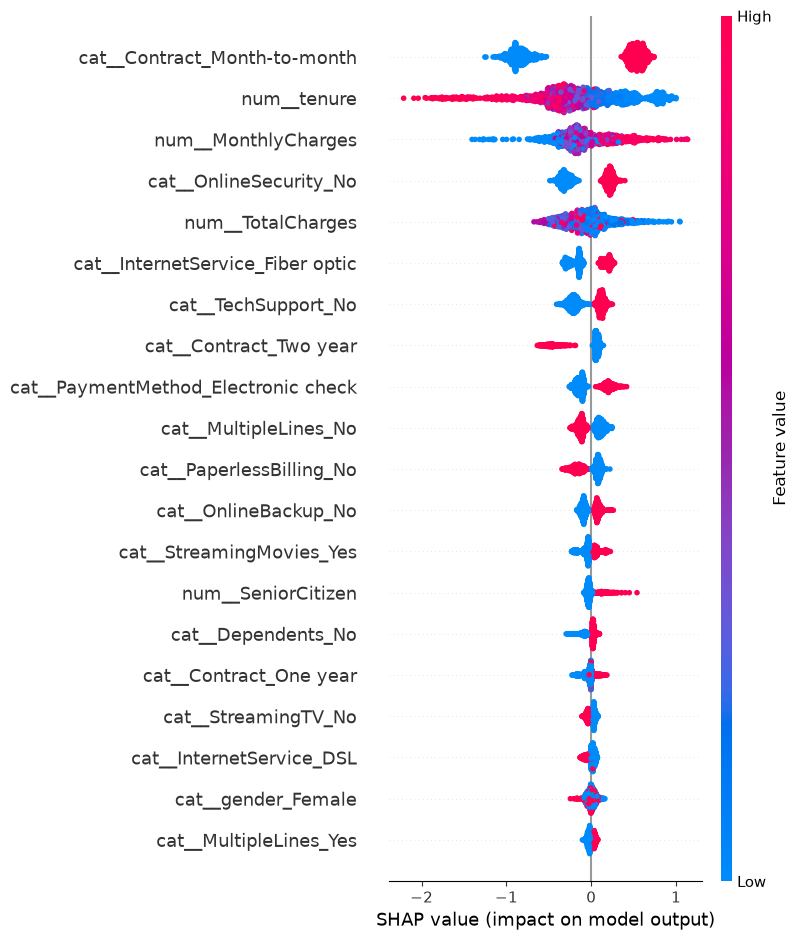

In [95]:
# ============================================
# STEP 20.7 — SHAP SUMMARY
# ============================================

shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names,
    show=True
)

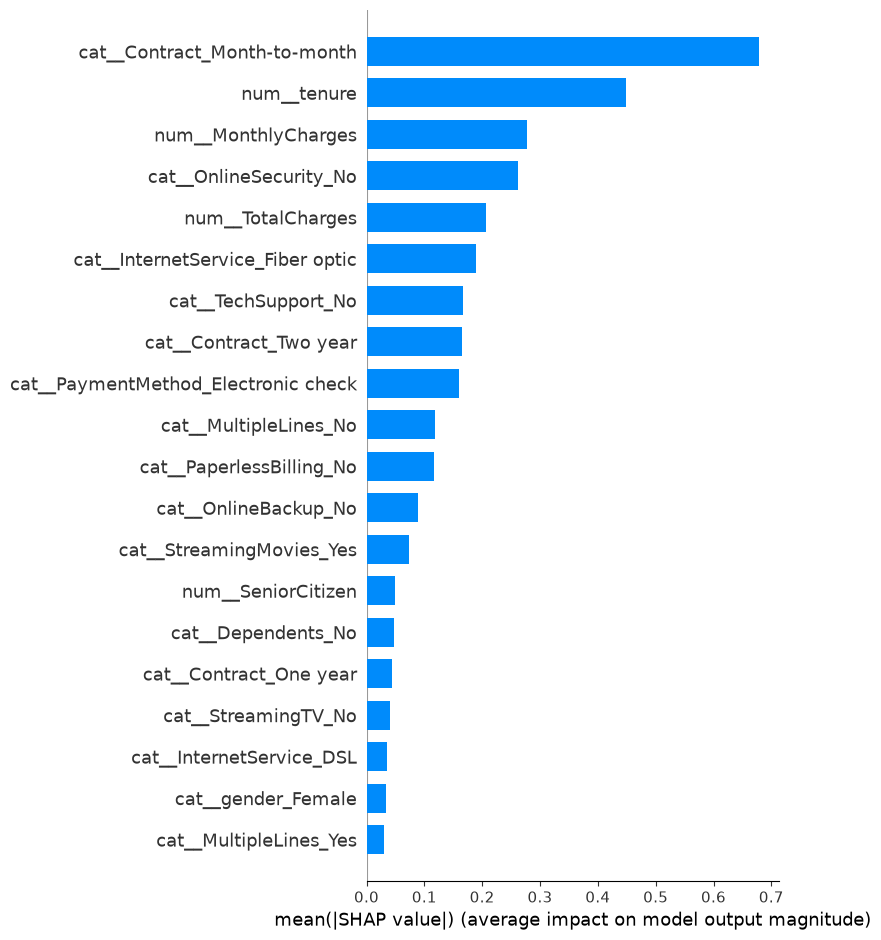

In [96]:
# ============================================
# STEP 20.8 — GLOBAL SHAP IMPORTANCE
# ============================================

shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names,
    plot_type="bar",
    show=True
)

In [97]:
# ============================================
# STEP 21.1 — FINAL MODEL COMPARISON
# ============================================

final_comparison = model_results.copy()

final_comparison = final_comparison.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

final_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.7388,0.5052,0.7834,0.6143,0.8418
1,XGBoost,0.7984,0.6471,0.5294,0.5824,0.8401
2,Random Forest,0.7622,0.5396,0.7112,0.6136,0.8335


In [98]:
# ============================================
# STEP 21.2 — PRODUCTION MODEL
# ============================================

production_model = xgb_pipeline

print("Production model selected: XGBoost")

Production model selected: XGBoost


In [99]:
# ============================================
# STEP 21.3 — PRODUCTION THRESHOLD
# ============================================

PRODUCTION_THRESHOLD = 0.25

print(
    f"Production churn threshold: "
    f"{PRODUCTION_THRESHOLD}"
)

Production churn threshold: 0.25


In [104]:
# ============================================
# STEP 21.4 — CUSTOMER CHURN PREDICTION
# ============================================

def predict_customer_churn(customer_data):
    
    probability = production_model.predict_proba(
        customer_data
    )[:, 1][0]

    prediction = int(
        probability >= PRODUCTION_THRESHOLD
    )

    if probability >= 0.70:
        risk_level = "High"
    elif probability >= 0.40:
        risk_level = "Medium"
    else:
        risk_level = "Low"

    return {
        "churn_probability": float(probability),
        "churn_prediction": prediction,
        "risk_level": risk_level
    }

In [105]:
# ============================================
# STEP 21.5 — TEST CUSTOMER PREDICTION
# ============================================

sample_customer = X_test.iloc[[0]]

result = predict_customer_churn(
    sample_customer
)

print(result)

{'churn_probability': 0.006250555627048016, 'churn_prediction': 0, 'risk_level': 'Low'}


In [107]:
# ============================================
# STEP 21.6 — BUSINESS RISK CLASSIFICATION
# ============================================

def classify_risk(probability):

    if probability >= 0.70:
        return "High Risk"

    elif probability >= 0.40:
        return "Medium Risk"

    else:
        return "Low Risk"

In [108]:
print(classify_risk(0.82))
print(classify_risk(0.56))
print(classify_risk(0.21))

High Risk
Medium Risk
Low Risk


In [109]:
# ============================================
# STEP 21.7 — COMPLETE BUSINESS PREDICTION
# ============================================

def generate_customer_prediction(customer_data):

    probability = production_model.predict_proba(
        customer_data
    )[:, 1][0]

    prediction = int(
        probability >= PRODUCTION_THRESHOLD
    )

    risk_level = classify_risk(probability)

    return {
        "churn_probability": round(
            float(probability), 4
        ),
        "churn_prediction": prediction,
        "risk_level": risk_level
    }

In [110]:
customer_result = generate_customer_prediction(
    X_test.iloc[[0]]
)

print(customer_result)

{'churn_probability': 0.0063, 'churn_prediction': 0, 'risk_level': 'Low Risk'}


In [111]:
# ============================================
# STEP 21.8 — RETENTION RECOMMENDATION
# ============================================

def retention_recommendation(risk_level):

    if risk_level == "High Risk":
        return (
            "Immediate retention intervention recommended."
        )

    elif risk_level == "Medium Risk":
        return (
            "Targeted retention offer or customer outreach recommended."
        )

    else:
        return (
            "Continue standard customer engagement."
        )

In [112]:
risk = customer_result["risk_level"]

print(
    retention_recommendation(risk)
)

Continue standard customer engagement.


In [113]:
# ============================================
# STEP 22.2 — SAVE PRODUCTION MODEL
# ============================================

import joblib
from pathlib import Path

MODEL_DIR = Path("../models")

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_PATH = MODEL_DIR / "churn_model.joblib"

joblib.dump(
    production_model,
    MODEL_PATH
)

print("Model saved successfully:")
print(MODEL_PATH)

Model saved successfully:
..\models\churn_model.joblib


In [114]:
# ============================================
# STEP 22.3 — SAVE THRESHOLD
# ============================================

import json

THRESHOLD_PATH = MODEL_DIR / "threshold.json"

with open(THRESHOLD_PATH, "w") as f:
    json.dump(
        {
            "production_threshold": PRODUCTION_THRESHOLD
        },
        f,
        indent=4
    )

print("Threshold saved successfully:")
print(THRESHOLD_PATH)

Threshold saved successfully:
..\models\threshold.json


In [115]:
# ============================================
# STEP 22.4 — SAVE FEATURE NAMES
# ============================================

FEATURE_NAMES_PATH = MODEL_DIR / "feature_names.json"

with open(FEATURE_NAMES_PATH, "w") as f:
    json.dump(
        feature_names.tolist(),
        f,
        indent=4
    )

print("Feature names saved successfully:")
print(FEATURE_NAMES_PATH)

Feature names saved successfully:
..\models\feature_names.json


In [116]:
# ============================================
# STEP 22.5 — VERIFY MODEL FILES
# ============================================

print("Model directory contents:")

for file in MODEL_DIR.iterdir():
    print(
        f"{file.name:<25} "
        f"{file.stat().st_size:,} bytes"
    )

Model directory contents:
churn_model.joblib        483,971 bytes
feature_names.json        1,568 bytes
threshold.json            38 bytes


In [117]:
# ============================================
# STEP 22.6 — LOAD MODEL TEST
# ============================================

loaded_model = joblib.load(
    MODEL_PATH
)

print("Saved model loaded successfully.")
print(type(loaded_model))

Saved model loaded successfully.
<class 'sklearn.pipeline.Pipeline'>


In [118]:
# ============================================
# STEP 22.7 — SAVED MODEL PREDICTION TEST
# ============================================

loaded_probability = loaded_model.predict_proba(
    X_test.iloc[[0]]
)[:, 1][0]

loaded_prediction = int(
    loaded_probability >= PRODUCTION_THRESHOLD
)

print(
    f"Churn probability: "
    f"{loaded_probability:.4f}"
)

print(
    f"Churn prediction: "
    f"{loaded_prediction}"
)

Churn probability: 0.0063
Churn prediction: 0


In [119]:
# ============================================
# STEP 22.8 — VERIFY THRESHOLD
# ============================================

with open(THRESHOLD_PATH, "r") as f:
    saved_config = json.load(f)

print(saved_config)

{'production_threshold': 0.25}
